# Классификация обращений клиентов RUDATA. Подход 1: TF-IDF + градиентный бустинг

НАЗВАНИЕ ПРОЕКТА: Интеллектуальная классификация и анализ клиентских обращений (задача 2.2.3)

ОПИСАНИЕ ИССЛЕДОВАНИЯ.
В поддержку RUDATA приходят обращения клиентов. Сейчас оператор вручную определяет,
с каким интерфейсом работает клиент, о каком продукте речь и какая тематика вопроса.
Сервис должен делать это автоматически по тексту обращения и логину клиента,
а сомнительные обращения отправлять на ручную проверку.

Цель исследования: по тексту обращения определить три поля из справочника —
интерфейс, продукт и тематику, — для каждого поля выдать уверенность
и признак «нужна ручная проверка».

Данные синтетические: 4 765 размеченных обращений с апреля по сентябрь 2026 года,
справочник допустимых значений (28 кодов) и доступы логинов к продуктам.

В этом ноутбуке — первый подход: классический классификатор, обученный на разметке.
Второй подход (локальная языковая модель) — в отдельном ноутбуке, далее сравнение.

## Перевод бизнес-задачи на язык машинного обучения

Вид задачи машинного обучения: многоклассовая классификация, три отдельные задачи —
по одной на каждое поле

Тип задачи: обучение с учителем

Объект: одно обращение клиента

Признаки: TF-IDF текста обращения (слова, пары слов и кусочки слов), сжатый SVD до 300 столбцов;
для тематики — отдельно, по тексту без названий продуктов и интерфейсов

Целевые переменные:
- `interface` — интерфейс, 7 классов;
- `product` — продукт, 8 классов;
- `topic` — тематика, 13 классов.

Модели: LightGBM, XGBoost и CatBoost, подбор гиперпараметров через Optuna на validation,
ранняя остановка по validation.

Доступы логина к продуктам учитываем после модели: продукты, которые логину не подключены,
вычёркиваем из вариантов.

Метрики: accuracy и macro-F1 по каждому полю, доля обращений, где верны все три поля,
доля ручной проверки и точность на обращениях, принятых автоматически.

## Загрузка необходимых библиотек

In [1]:
# Общее
import pandas as pd  # работа с датафреймами
import numpy as np  # математика
from matplotlib import pyplot as plt  # графики
import seaborn as sns  # графики
import os  # папки
import re  # регулярные выражения для очистки текста
import json  # справочник доступов и параметры модели
import time  # замер скорости
import joblib  # сохранение моделей
import warnings  # отключение лишних предупреждений

# Текст
from sklearn.feature_extraction.text import TfidfVectorizer  # TF-IDF
from scipy.sparse import hstack  # склейка двух TF-IDF матриц в одну
from sklearn.decomposition import TruncatedSVD  # сжатие TF-IDF до 300 столбцов

# МО
from catboost import CatBoostClassifier  # градиентный бустинг CatBoost
from lightgbm import LGBMClassifier, early_stopping  # градиентный бустинг LightGBM и его ранняя остановка
from xgboost import XGBClassifier  # градиентный бустинг XGBoost
import optuna  # подбор гиперпараметров

# Метрики
from sklearn.metrics import accuracy_score, f1_score  # accuracy и macro-F1
from sklearn.metrics import classification_report, ConfusionMatrixDisplay  # отчёт по классам, матрица ошибок

optuna.logging.set_verbosity(optuna.logging.WARNING)  # не печатаем каждую попытку Optuna
pd.set_option('display.max_colwidth', 200)  # показываем тексты обращений целиком
warnings.filterwarnings('ignore', message="The argument 'eval_set' is deprecated")  # лишние предупреждения LightGBM

Зафиксируем константы задачи в одном месте

In [2]:
rand_state = 42  # фиксируем random_state

FIELDS = ['interface', 'product', 'topic']  # три поля, которые классифицируем
SPECIFIC_PRODUCTS = ['RD_RISK', 'RD_SOLVENCY', 'RDFOR', 'RD_SCORE', 'RD_AFFILIATE', 'SPPI_TEST']  # шесть продуктов

SVD_COMPONENTS = 300  # до скольких столбцов сжимаем TF-IDF
N_TRIALS = 10  # попыток Optuna на одну модель для одного поля
TUNING_TIMEOUT = 15 * 60  # не дольше 15 минут на подбор одной модели для одного поля, в секундах
EARLY_STOPPING = 50  # останавливаем обучение, если 50 деревьев подряд не улучшили качество на validation
TARGET_AUTO_ACCURACY = 0.95  # какую долю полностью верных ответов хотим среди принятых автоматически

os.makedirs('models', exist_ok=True)
os.makedirs('results', exist_ok=True)

## Загрузка данных

In [3]:
appeals = pd.read_csv('data/raw/appeals.csv', encoding='utf-8-sig', parse_dates=['created_at'])
dictionary = pd.read_csv('data/raw/dictionary.csv', encoding='utf-8-sig')

In [4]:
df_names = ['appeals', 'dictionary']
dfs = [appeals, dictionary]

for name, df in zip(df_names, dfs):
    display(f'Датасет {name}: {df.shape[0]} строк, {df.shape[1]} колонок')
    display(df.head())

'Датасет appeals: 4765 строк, 9 колонок'

,appeal_id,created_at,client_id,text,available_products,interface,product,topic,split
0,AF4F52DB7B4CAD9,2026-04-01 08:19:18+03:00,rd_user_0098,"Вопрос не о надстройке Excel, а о нашем HTTP-клиенте. API RUDATA, наш программный клиент. Как получить большой список инструментов порциями и не повторять уже загруженные записи? Нужен рекомендуем...","[""RD_AFFILIATE"",""RD_RISK"",""RD_SCORE"",""RD_SOLVENCY"",""SPPI_TEST""]",API,NO_PRODUCT,HOW_TO,train
1,A22AAF00676C853,2026-04-01 09:21:55+03:00,rd_user_0070,"Добрый день. Помогите разобраться в RD Score: следует ли трактовать PD как кредитный рейтинг? Интерфейс работает, вопрос только к смыслу. По возможности ответьте в этой переписке.","[""RD_SCORE""]",NONE,RD_SCORE,METHODOLOGY,train
2,A4750C0238BF6F9,2026-04-01 10:24:35+03:00,rd_user_0029,"Добрый день.\nПомогите разобраться в РД Скор: следует ли трактовать PD как кредитный рейтинг? Интерфейс работает, вопрос только к смыслу.\nПо возможности ответьте в этой переписке.","[""RD_SCORE""]",NONE,RD_SCORE,METHODOLOGY,train
3,AC71B8439C4EB91,2026-04-01 10:45:36+03:00,rd_user_0027,"Добрый день.\nРечь о шаблоне Add-In, не об установке надстройки. RD Affiliate формирует цепочки по 18 компаниям за 150 секунд, хотя раньше было быстрее. Выгрузка завершается.\nОтвет нужен для даль...","[""RD_AFFILIATE""]",EXCEL_TEMPLATE,RD_AFFILIATE,PERFORMANCE,train
4,AA39C512C83BBFC,2026-04-01 10:57:42+03:00,rd_user_0098,"Здравствуйте.\n\nРечь о шаблоне Add-In, не об установке надстройки. RD Affiliate формирует цепочки по 12 компаниям за 60 секунд, хотя раньше было быстрее. Выгрузка завершается.\n\nСейчас собираю м...","[""RD_AFFILIATE"",""RD_RISK"",""RD_SCORE"",""RD_SOLVENCY"",""SPPI_TEST""]",EXCEL_TEMPLATE,RD_AFFILIATE,PERFORMANCE,train


'Датасет dictionary: 28 строк, 6 колонок'

,field,code,name,description,annotation_rule,source_url
0,interface,API,API RUDATA,"Удалённые HTTP/REST-запросы, JSON, токен, Swagger.",HTTP API; не COM/VBA в Excel. В данной учебной онтологии продукт NO_PRODUCT.,https://rudata.info/interface/api/
1,interface,WEB,WEB RUDATA,"Сайт, браузерный поиск и портфель.",Проблема на сайте; выгрузка из сайта в Excel остаётся WEB.,https://rudata.info/interface/
2,interface,EXCEL_ADDIN,Надстройка Excel Add-In,"Установка, активация, функции, COM API, соединение надстройки.","Общий уровень надстройки, не содержимое готового расчётного шаблона.",https://rudata.info/add-in-install/
3,interface,EXCEL_TEMPLATE,Шаблон Excel Add-In,Готовая книга/шаблон расчёта или получения данных.,Работа конкретного шаблона; не отдельная HTTP-ручка.,https://rudata.info/rules-help/
4,interface,EFIR,Терминал ЭФИР,Установленное терминальное приложение.,"Не любая надстройка с названием ЭФИР, а самостоятельный терминал.",https://rudata.info/terminal-install/


Проверим данные: уникальность `appeal_id`, пропуски и то, что все метки есть в справочнике

In [5]:
display(f'Дубликатов appeal_id: {appeals["appeal_id"].duplicated().sum()}')
display(f'Пропусков: {appeals.isna().sum().sum()}')

for field in FIELDS:
    codes = dictionary.loc[dictionary['field'] == field, 'code']
    display(f'{field}: классов в справочнике {len(codes)}, меток вне справочника {(~appeals[field].isin(codes)).sum()}')

'Дубликатов appeal_id: 0'

'Пропусков: 0'

'interface: классов в справочнике 7, меток вне справочника 0'

'product: классов в справочнике 8, меток вне справочника 0'

'topic: классов в справочнике 13, меток вне справочника 0'

In [6]:
appeals.groupby('split')['created_at'].agg(['count', 'min', 'max'])

,count,min,max
split,,,
test,905,2026-09-01 09:09:49+03:00,2026-09-30 18:03:08+03:00
train,3030,2026-04-01 08:19:18+03:00,2026-07-31 18:59:50+03:00
validation,830,2026-08-01 09:07:33+03:00,2026-08-31 17:28:04+03:00


**Вывод:** данные чистые — дубликатов и пропусков нет, все метки есть в справочнике.
Разбиение уже сделано по времени: train — апрель–июль, validation — август, test — сентябрь.
Его и используем: случайно перемешивать строки нельзя, иначе проверка на новых формулировках
будет нечестной

## Справочник «логин → доступные продукты»

По постановке сервис получает на вход только текст и логин, а доступы берёт из своего справочника.
Отдельным файлом справочник не дали, но его можно собрать из `appeals.csv`:
у одного логина список доступов всегда одинаковый. Проверим это

In [7]:
# в CSV список доступов записан строкой '["RD_RISK","RD_SCORE"]' — превращаем в список Python
appeals['available_products'] = appeals['available_products'].apply(json.loads)
appeals['n_available'] = appeals['available_products'].apply(len)

# сколько разных списков доступов у каждого логина (должен быть ровно один)
lists_per_login = appeals.groupby('client_id')['available_products'].apply(lambda x: x.apply(tuple).nunique())
display(f'Логинов: {len(lists_per_login)}, из них с разными списками доступов: {(lists_per_login > 1).sum()}')

'Логинов: 240, из них с разными списками доступов: 0'

In [8]:
# собираем справочник и сохраняем — его будет использовать сервис.
# В этих данных список у логина один (проверили выше), но на реальных данных доступы меняются со временем,
# поэтому берём самый свежий список — из последнего по времени обращения логина
access = (appeals.sort_values('created_at')
          .groupby('client_id')['available_products'].last()
          .to_dict())

with open('models/access.json', 'w', encoding='utf-8') as f:
    json.dump(access, f, ensure_ascii=False, indent=1)

list(access.items())[:3]

[('rd_user_0001', []), ('rd_user_0002', []), ('rd_user_0003', [])]

Проверим, как продукт связан с доступами:
- входит ли конкретный продукт в доступы логина;
- при каком числе доступов встречается продукт `UNKNOWN`

In [9]:
specific = appeals['product'].isin(SPECIFIC_PRODUCTS)
in_access = appeals[specific].apply(lambda row: row['product'] in row['available_products'], axis=1)
display(f'Конкретный продукт входит в доступы логина: {in_access.mean():.0%}')

pd.crosstab(appeals['n_available'], appeals['product'] == 'UNKNOWN').rename(
    columns={False: 'другой продукт', True: 'product = UNKNOWN'})

'Конкретный продукт входит в доступы логина: 100%'

product,другой продукт,product = UNKNOWN
n_available,,
0,436,0
1,1417,0
2,540,44
3,868,65
4,659,43
5,476,28
6,180,9


**Вывод:** у каждого логина один список доступов, справочник собран и сохранён в `models/access.json`.
Конкретный продукт всегда входит в доступы логина — значит, недоступные продукты можно
смело вычёркивать из вариантов модели. Продукт `UNKNOWN` встречается только при 2+ доступах:
при одном доступе неясности «о каком продукте речь» не бывает

## Исследовательский анализ данных

### Распределение классов

In [10]:
for field in FIELDS:
    display(pd.crosstab(appeals[field], appeals['split'], normalize='columns').round(3)
            .sort_values('train', ascending=False))

split,test,train,validation
interface,,,
EXCEL_TEMPLATE,0.471,0.410,0.396
API,0.199,0.156,0.142
NONE,0.074,0.152,0.083
UNKNOWN,0.038,0.088,0.053
EXCEL_ADDIN,0.069,0.079,0.099
WEB,0.048,0.072,0.152
EFIR,0.103,0.045,0.075


split,test,train,validation
product,,,
NO_PRODUCT,0.492,0.372,0.551
RD_SCORE,0.051,0.107,0.095
RD_RISK,0.054,0.098,0.083
RD_AFFILIATE,0.104,0.098,0.061
RDFOR,0.065,0.097,0.060
RD_SOLVENCY,0.083,0.096,0.051
SPPI_TEST,0.114,0.094,0.046
UNKNOWN,0.038,0.037,0.053


split,test,train,validation
topic,,,
DATA_MISSING,0.149,0.170,0.069
AVAILABILITY,0.223,0.122,0.071
METHODOLOGY,0.051,0.097,0.172
AUTH_ACCESS,0.060,0.095,0.153
CONFIG_INTEGRATION,0.063,0.095,0.047
PERFORMANCE,0.152,0.076,0.096
HOW_TO,0.071,0.071,0.148
FEATURE_REQUEST,0.051,0.070,0.041
CONTRACT,0.060,0.069,0.047


Классы несбалансированы: например, в интерфейсе `EXCEL_TEMPLATE` занимает ~40%, `WEB` и `EFIR` — по несколько процентов.
Поэтому главная метрика — macro-F1: она считает F1 по каждому классу отдельно и усредняет,
так что редкие классы весят столько же, сколько частые. Accuracy смотрим как дополнительную.

Доли классов меняются от месяца к месяцу: например, в тематике `AVAILABILITY` в test (сентябрь)
заметно больше, чем в validation (август). Это похоже на всплеск обращений — пригодится
в блоке всплесков. Для классификации это значит, что качество на test может отличаться от validation

### Длина текстов

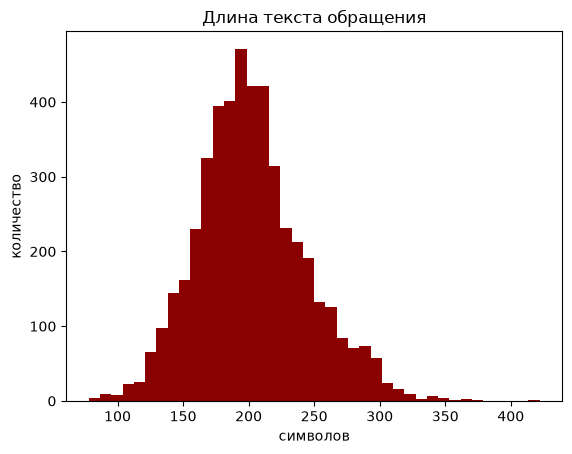

count    4765.000000
mean      202.314166
std        41.564843
min        78.000000
25%       175.000000
50%       199.000000
75%       226.000000
max       422.000000
Name: text_len, dtype: float64

In [11]:
appeals['text_len'] = appeals['text'].str.len()

appeals['text_len'].plot(kind='hist', bins=40, color='darkred')
plt.title('Длина текста обращения')
plt.xlabel('символов')
plt.ylabel('количество')
plt.show()

appeals['text_len'].describe()

Обращения короткие: в среднем около 200 символов, максимум ~420

### Связь интерфейса и продукта

In [12]:
pd.crosstab(appeals['interface'], appeals['product'])

product,NO_PRODUCT,RDFOR,RD_AFFILIATE,RD_RISK,RD_SCORE,RD_SOLVENCY,SPPI_TEST,UNKNOWN
interface,,,,,,,,
API,770,0,0,0,0,0,0,0
EFIR,290,0,0,0,0,0,0,0
EXCEL_ADDIN,382,0,0,0,0,0,0,0
EXCEL_TEMPLATE,0,308,356,316,336,310,318,53
NONE,200,61,63,61,72,62,77,0
UNKNOWN,0,35,24,39,42,37,31,136
WEB,386,0,0,0,0,0,0,0


Поля связаны жёсткими правилами разметки:
- `API`, `WEB`, `EFIR`, `EXCEL_ADDIN` → продукт всегда `NO_PRODUCT`;
- `EXCEL_TEMPLATE` и `UNKNOWN` → конкретный продукт или `UNKNOWN`, но никогда не `NO_PRODUCT`;
- `NONE` (договор, методология) → любой продукт.

Это готовая проверка ответа модели: если предсказания полей противоречат друг другу,
отправим обращение на ручную проверку.

Важно: это соглашения учебной разметки, а не свойства реальной системы RUDATA.
Например, `API → NO_PRODUCT` README прямо называет соглашением задачи: в реальности
продуктовые данные можно получать и через API. Поэтому правила мы используем мягко —
противоречие отправляет обращение на ручную проверку, но ответ модели не меняет.
На реальных данных правила нужно согласовать с заказчиком; если они не подтвердятся,
худшее последствие — лишние обращения на ручной проверке, а не неверные метки

### Поток обращений по дням

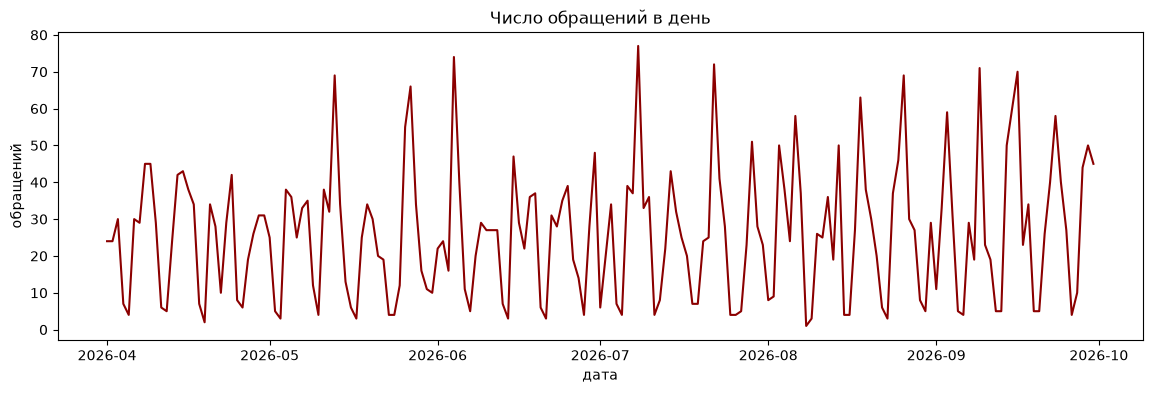

In [13]:
appeals['date'] = appeals['created_at'].dt.date

appeals.groupby('date')['appeal_id'].count().plot(figsize=(14, 4), color='darkred')
plt.title('Число обращений в день')
plt.xlabel('дата')
plt.ylabel('обращений')
plt.show()

### Примеры обращений

In [14]:
appeals.sample(5, random_state=rand_state)[['text', 'available_products'] + FIELDS]

,text,available_products,interface,product,topic
964,"Здравствуйте.\n\nВопрос по готовому Excel-шаблону. Сохранённый и новый результаты SPPI расходятся, хотя дату и настройки не меняли. Нужна проверка примера.\n\nХотим разобраться до следующей регуля...",[SPPI_TEST],EXCEL_TEMPLATE,SPPI_TEST,DATA_DISCREPANCY
3355,Открываю готовый шаблон в Excel Add-In. Осваиваю RDFOR и ищу способ перейти от итогового показателя к составляющим. Как это сделать в шаблоне? Данные используем для внутренней сверки.,"[RDFOR, RD_AFFILIATE, RD_SCORE]",EXCEL_TEMPLATE,RDFOR,HOW_TO
2596,"Здравствуйте. Речь о шаблоне Add-In, не об установке надстройки. Просим добавить в RDFOR выгрузку только нарушенных лимитов с пользовательскими комментариями. Это пожелание к развитию. Ответ нужен...",[RDFOR],EXCEL_TEMPLATE,RDFOR,FEATURE_REQUEST
3961,"Коллеги, добрый день. Открываю готовый Excel-шаблон единственного продукта, подключённого к моему логину. В итоговой таблице отсутствует часть строк. Нужна проверка полноты результата. Ответ нужен...",[RD_SCORE],EXCEL_TEMPLATE,RD_SCORE,DATA_MISSING
598,"Отправляю HTTP-запросы к API RUDATA. Отправляем запрос на добавление отсутствующего выпуска в справочник API. Это вопрос данных, не разработки нового метода. Пока не передаю конфиденциальные сведе...","[RDFOR, RD_AFFILIATE, RD_SCORE]",API,NO_PRODUCT,DATA_MISSING


**Вывод:** тексты короткие и шаблонные, с перефразами и опечатками («RD Score» / «РД Скор»).
Часто в тексте есть прямые подсказки: «речь о шаблоне Add-In, не об установке надстройки».
Поэтому подход на словах и кусочках слов (TF-IDF) должен работать хорошо

## Подготовка признаков: TF-IDF

TF-IDF превращает текст в строку чисел:
у каждого слова свой столбец, а значение показывает, насколько слово важно для этого текста.
Слово получает большой вес, если оно часто встречается в этом обращении и редко в остальных.
Например, «шаблон» в обращении про шаблон получит заметный вес, а «добрый день» почти ничего не весит,
потому что встречается везде.

Сделаем два набора столбцов и склеим их:
- слова и пары слов (`ngram_range=(1, 2)`) — «шаблон», «не открывается», «rd score»;
- кусочки слов по 3–5 букв (`char_wb`) — помогают с опечатками и формами слов:
  «шаблон», «шаблона», «шаблоне» дают общие кусочки «шаб», «абл», «блон».

Перед этим немного почистим текст: нижний регистр, «ё» → «е», переносы строк → пробел

In [15]:
def clean_text(text):
    text = text.lower().replace('ё', 'е')
    text = re.sub(r'\s+', ' ', text)  # переносы строк и двойные пробелы — в один пробел
    return text.strip()


appeals['text_clean'] = appeals['text'].apply(clean_text)
appeals[['text', 'text_clean']].head(2)

,text,text_clean
0,"Вопрос не о надстройке Excel, а о нашем HTTP-клиенте. API RUDATA, наш программный клиент. Как получить большой список инструментов порциями и не повторять уже загруженные записи? Нужен рекомендуем...","вопрос не о надстройке excel, а о нашем http-клиенте. api rudata, наш программный клиент. как получить большой список инструментов порциями и не повторять уже загруженные записи? нужен рекомендуем..."
1,"Добрый день. Помогите разобраться в RD Score: следует ли трактовать PD как кредитный рейтинг? Интерфейс работает, вопрос только к смыслу. По возможности ответьте в этой переписке.","добрый день. помогите разобраться в rd score: следует ли трактовать pd как кредитный рейтинг? интерфейс работает, вопрос только к смыслу. по возможности ответьте в этой переписке."


Для тематики сделаем отдельный текст — без слов контекста. Модель тематики на полном тексте
запоминает не суть проблемы, а окружение: в train тема «не работает» чаще встречалась с API,
и модель выучила «API → AVAILABILITY». В validation и test та же тема приходит из Excel-шаблонов,
и подсказка ломается.

Поэтому для тематики убираем названия продуктов, интерфейсов и предметные слова
(«шаблон», «API», «RD Score», «контрагенты», «портфель»…) и оставляем слова о сути:
«ошибка», «медленно», «секунд», «не совпадает», «нет данных». Интерфейс и продукт
по-прежнему определяем по полному тексту — для них эти слова как раз главные.

Список слов подобран по смыслу и проверен на validation: простая модель тематики на таком тексте
дала macro-F1 0,42 против 0,32 на полном тексте. Названия продуктов вырезаем целиком
(«рд скор»), чтобы не задеть похожие слова («скорость»)

In [16]:
# слова контекста: названия продуктов, интерфейсы и предметные слова — для тематики это шум
CONTEXT_PATTERN = (
    r'\b(rd (risk|affiliate|score|solvency)|rdfor|sppi[\w-]*|рд (риск|аффилиат|скор|солвенси)|рдфор|сппи[\w-]*|'
    r'api|http\w*|json|rest|python|swagger|excel\w*|add-in|надстройк\w*|шаблон\w*|книг\w*|'
    r'сайт\w*|браузер\w*|web|эфир\w*|терминал\w*|'
    r'контрагент\w*|бумаг\w*|выпуск\w*|облигац\w*|портфел\w*|лимит\w*|нфо|pd|lgd|компани\w*|сервис\w*|продукт\w*)\b'
)


def remove_context(text):
    text = re.sub(CONTEXT_PATTERN, ' ', text)
    return re.sub(r'\s+', ' ', text).strip()


appeals['text_topic'] = appeals['text_clean'].apply(remove_context)
appeals[['text_clean', 'text_topic']].iloc[[3]]

,text_clean,text_topic
3,"добрый день. речь о шаблоне add-in, не об установке надстройки. rd affiliate формирует цепочки по 18 компаниям за 150 секунд, хотя раньше было быстрее. выгрузка завершается. ответ нужен для дальне...","добрый день. речь о , не об установке . формирует цепочки по 18 за 150 секунд, хотя раньше было быстрее. выгрузка завершается. ответ нужен для дальнейшей работы."


In [17]:
train = appeals[appeals['split'] == 'train']
valid = appeals[appeals['split'] == 'validation']
test = appeals[appeals['split'] == 'test']

display(f'train {len(train)}, validation {len(valid)}, test {len(test)}')

'train 3030, validation 830, test 905'

TF-IDF обучаем только на train: какие слова есть в словаре и их веса знаем только по обучающей выборке.
Validation и test только преобразуем — так же, как сервис будет преобразовывать новые обращения

In [18]:
tfidf_word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000)  # слова и пары слов
tfidf_char = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=5000)  # кусочки слов

tfidf_word.fit(train['text_clean'])
tfidf_char.fit(train['text_clean'])


def make_tfidf(texts):
    """Текст → матрица TF-IDF: столбцы по словам и по кусочкам слов"""
    return hstack([tfidf_word.transform(texts), tfidf_char.transform(texts)]).tocsr().astype(np.float32)


X_train_tfidf = make_tfidf(train['text_clean'])
display(f'Столбцов TF-IDF: {X_train_tfidf.shape[1]} (слова {len(tfidf_word.vocabulary_)}, кусочки {len(tfidf_char.vocabulary_)})')

'Столбцов TF-IDF: 10000 (слова 5000, кусочки 5000)'

### Сжатие TF-IDF до 300 столбцов (SVD)

В TF-IDF 10 000 столбцов, и почти все значения — нули: в коротком обращении встречается
лишь несколько десятков слов из словаря. Бустинг на таких данных учится очень медленно:
на каждом шаге он перебирает все 10 000 столбцов. Без сжатия подбор всех моделей
занимал больше 16 часов.

SVD (сингулярное разложение) сжимает 10 000 столбцов в 300 «смысловых»:
слова, которые часто встречаются вместе («шаблон», «excel», «книга»), объединяются
в один столбец. Получается плотная таблица 300 чисел на обращение, и бустинг
учится в десятки раз быстрее. Часть информации при сжатии теряется — сколько
сохранилось, покажет доля объяснённой дисперсии.

SVD, как и TF-IDF, обучаем только на train

In [19]:
svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=rand_state)
svd.fit(X_train_tfidf)

display(f'Сохранено информации (доля объяснённой дисперсии): {svd.explained_variance_ratio_.sum():.0%}')


def make_features(texts):
    """Текст → TF-IDF → 300 столбцов SVD. Эту же функцию будет использовать сервис"""
    return svd.transform(make_tfidf(texts))


X_train_full = make_features(train['text_clean'])
X_valid_full = make_features(valid['text_clean'])
X_test_full = make_features(test['text_clean'])

display(f'train {X_train_full.shape}, validation {X_valid_full.shape}, test {X_test_full.shape}')

'Сохранено информации (доля объяснённой дисперсии): 97%'

'train (3030, 300), validation (830, 300), test (905, 300)'

### Отдельные признаки для тематики

Те же шаги — TF-IDF по словам и кусочкам слов, затем SVD до 300 столбцов, — но на тексте без слов контекста.
Обучаем только на train

In [20]:
tfidf_word_topic = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000)
tfidf_char_topic = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=5000)

tfidf_word_topic.fit(train['text_topic'])
tfidf_char_topic.fit(train['text_topic'])


def make_tfidf_topic(texts):
    return hstack([tfidf_word_topic.transform(texts), tfidf_char_topic.transform(texts)]).tocsr().astype(np.float32)


svd_topic = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=rand_state)
svd_topic.fit(make_tfidf_topic(train['text_topic']))


def make_features_topic(texts):
    """Текст без слов контекста → TF-IDF → 300 столбцов SVD (только для тематики)"""
    return svd_topic.transform(make_tfidf_topic(texts))

Собираем признаки в словари «поле → признаки»: интерфейс и продукт — по полному тексту,
тематика — по тексту без контекста. Дальше везде берём `X_train[field]`

In [21]:
X_train = {'interface': X_train_full, 'product': X_train_full, 'topic': make_features_topic(train['text_topic'])}
X_valid = {'interface': X_valid_full, 'product': X_valid_full, 'topic': make_features_topic(valid['text_topic'])}
X_test = {'interface': X_test_full, 'product': X_test_full, 'topic': make_features_topic(test['text_topic'])}

{field: X_train[field].shape for field in FIELDS}

{'interface': (3030, 300), 'product': (3030, 300), 'topic': (3030, 300)}

Целевые переменные переведём в номера классов: бустинги работают и с текстом, но не XGBoost - ему нужно передавать числа.
Порядок классов берём из справочника

In [22]:
classes = {field: dictionary.loc[dictionary['field'] == field, 'code'].tolist() for field in FIELDS}
code_to_num = {field: {code: num for num, code in enumerate(classes[field])} for field in FIELDS}

y_train = {field: train[field].map(code_to_num[field]).values for field in FIELDS}
y_valid = {field: valid[field].map(code_to_num[field]).values for field in FIELDS}
y_test = {field: test[field].map(code_to_num[field]).values for field in FIELDS}

y_train

{'interface': array([0, 5, 5, ..., 3, 2, 1], shape=(3030,)),
 'product': array([6, 3, 3, ..., 3, 6, 6], shape=(3030,)),
 'topic': array([8, 7, 7, ..., 2, 9, 8], shape=(3030,))}

## Обучение моделей

Для каждого из трёх полей обучаем три бустинга: LightGBM, XGBoost и CatBoost.
Каждая модель — в своём разделе.

Гиперпараметры подбирает Optuna: обучаем на train, качество меряем на validation по macro-F1.
Test не трогаем до финальной оценки.

Что ещё ускоряет обучение, кроме SVD:
- **ранняя остановка** — число деревьев не подбираем. Модель добавляет деревья, пока качество
  на validation растёт, и останавливается, если `EARLY_STOPPING` деревьев подряд не дали улучшения;
- **ограничение по времени** — подбор одной модели для одного поля идёт не дольше `TUNING_TIMEOUT`.
  Если время вышло раньше `N_TRIALS` попыток, Optuna берёт лучшее из того, что успела.


Функция метрик и функция обучения одной модели. `fit_model` создаёт модель по названию,
обучает на train и использует validation для ранней остановки

In [23]:
def metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    return accuracy, macro_f1


def fit_model(model_name, params, field):
    if model_name == 'lightgbm':
        model = LGBMClassifier(**params, n_estimators=2000, random_state=rand_state, verbose=-1)
        model.fit(X_train[field], y_train[field], eval_set=[(X_valid[field], y_valid[field])],
                  callbacks=[early_stopping(EARLY_STOPPING, verbose=False)])
    if model_name == 'xgboost':
        model = XGBClassifier(**params, n_estimators=2000, early_stopping_rounds=EARLY_STOPPING,
                              tree_method='hist', random_state=rand_state)
        model.fit(X_train[field], y_train[field], eval_set=[(X_valid[field], y_valid[field])], verbose=False)
    if model_name == 'catboost':
        model = CatBoostClassifier(**params, iterations=2000, early_stopping_rounds=EARLY_STOPPING,
                                   loss_function='MultiClass', random_seed=rand_state,
                                   verbose=0, allow_writing_files=False)
        model.fit(X_train[field], y_train[field], eval_set=(X_valid[field], y_valid[field]))
    return model

Функция `tune` — подбор для одной модели и одного поля:
1. Optuna перебирает параметры и для каждой попытки считает macro-F1 на validation;
2. модель с лучшими параметрами обучается заново, замеряем время обучения и прогноза;
3. возвращаем строку с результатами и обученную модель.

Результаты складываем в словари `results` и `best_models` с ключом (поле, модель)

In [24]:
results = {}  # (поле, модель) → строка с метриками и временем
best_models = {}  # (поле, модель) → обученная модель


def tune(model_name, objective, field):
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=rand_state))
    start = time.time()
    study.optimize(lambda trial: objective(trial, field), n_trials=N_TRIALS, timeout=TUNING_TIMEOUT)
    tuning_time = time.time() - start

    # переобучаем с лучшими параметрами и замеряем время
    start = time.time()
    model = fit_model(model_name, study.best_params, field)
    fit_time = time.time() - start

    start = time.time()
    y_pred = model.predict_proba(X_valid[field]).argmax(axis=1)
    predict_time = time.time() - start

    accuracy, macro_f1 = metrics(y_valid[field], y_pred)
    display(f'{model_name} / {field}: macro-F1 {macro_f1:.3f}, попыток {len(study.trials)}, '
            f'подбор {tuning_time / 60:.1f} мин')

    row = {'field': field, 'model': model_name, 'accuracy': accuracy, 'macro_f1': macro_f1,
           'tuning_min': tuning_time / 60, 'fit_sec': fit_time,
           'predict_ms_per_appeal': predict_time / len(valid) * 1000, 'params': study.best_params}
    return row, model

### LightGBM

In [25]:
def objective_lightgbm(trial, field):
    params_lightgbm = {
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 30),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
    }
    model = fit_model('lightgbm', params_lightgbm, field)
    y_pred = model.predict_proba(X_valid[field]).argmax(axis=1)
    return f1_score(y_valid[field], y_pred, average='macro')

In [26]:
for field in FIELDS:
    row, model = tune('lightgbm', objective_lightgbm, field)
    results[(field, 'lightgbm')] = row
    best_models[(field, 'lightgbm')] = model

'lightgbm / interface: macro-F1 0.812, попыток 10, подбор 0.4 мин'

'lightgbm / product: macro-F1 0.807, попыток 10, подбор 0.6 мин'

'lightgbm / topic: macro-F1 0.372, попыток 10, подбор 0.6 мин'

### XGBoost

In [27]:
def objective_xgboost(trial, field):
    params_xgboost = {
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
    }
    model = fit_model('xgboost', params_xgboost, field)
    y_pred = model.predict_proba(X_valid[field]).argmax(axis=1)
    return f1_score(y_valid[field], y_pred, average='macro')

In [28]:
for field in FIELDS:
    row, model = tune('xgboost', objective_xgboost, field)
    results[(field, 'xgboost')] = row
    best_models[(field, 'xgboost')] = model

'xgboost / interface: macro-F1 0.845, попыток 10, подбор 1.5 мин'

'xgboost / product: macro-F1 0.806, попыток 10, подбор 1.7 мин'

'xgboost / topic: macro-F1 0.502, попыток 10, подбор 3.5 мин'

### CatBoost

Самый медленный из трёх бустингов

In [29]:
def objective_catboost(trial, field):
    params_catboost = {
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.3, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10, log=True),
    }
    model = fit_model('catboost', params_catboost, field)
    y_pred = model.predict_proba(X_valid[field]).argmax(axis=1)
    return f1_score(y_valid[field], y_pred, average='macro')

In [30]:
for field in FIELDS:
    row, model = tune('catboost', objective_catboost, field)
    results[(field, 'catboost')] = row
    best_models[(field, 'catboost')] = model

'catboost / interface: macro-F1 0.834, попыток 3, подбор 18.1 мин'

'catboost / product: macro-F1 0.826, попыток 3, подбор 21.5 мин'

'catboost / topic: macro-F1 0.443, попыток 3, подбор 30.4 мин'

### Сравнение моделей

Сравниваем модели по качеству на validation и по скорости

In [31]:
res = pd.DataFrame(results.values())
res.pivot(index='model', columns='field', values='macro_f1').round(3)

field,interface,product,topic
model,,,
catboost,0.834,0.826,0.443
lightgbm,0.812,0.807,0.372
xgboost,0.845,0.806,0.502


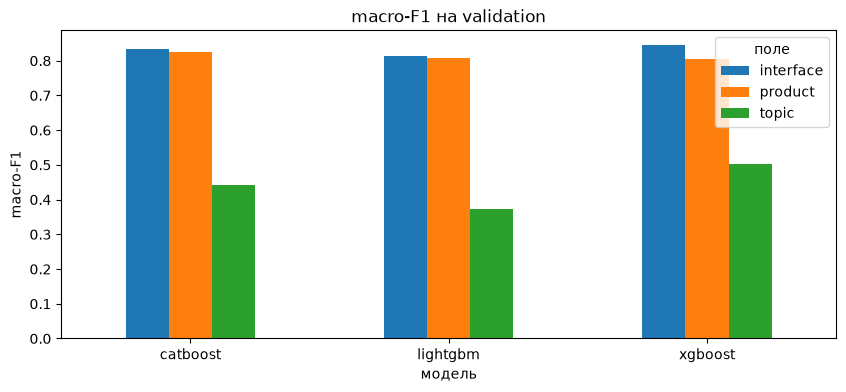

In [32]:
res.pivot(index='model', columns='field', values='macro_f1').plot(kind='bar', figsize=(10, 4))
plt.title('macro-F1 на validation')
plt.xlabel('модель')
plt.ylabel('macro-F1')
plt.xticks(rotation=0)
plt.legend(title='поле')
plt.show()

In [33]:
res.groupby('model')[['tuning_min', 'fit_sec', 'predict_ms_per_appeal']].mean().round(2)

,tuning_min,fit_sec,predict_ms_per_appeal
model,,,
catboost,23.30,18.81,0.00
lightgbm,0.54,4.67,0.01
xgboost,2.22,10.50,0.01


Для каждого поля выбираем модель с лучшим macro-F1 на validation.

Оговорка: validation используется и для ранней остановки, и для подбора параметров, и для выбора модели,
поэтому качество на ней немного завышено. Честная оценка — только на test

In [34]:
best_by_field = res.loc[res.groupby('field')['macro_f1'].idxmax()].set_index('field')['model'].to_dict()
best_by_field

{'interface': 'xgboost', 'product': 'catboost', 'topic': 'xgboost'}

**Вывод:**
- Интерфейс и продукт бустинги определяют хорошо: macro-F1 0,81–0,85. Лучшие на validation — XGBoost
  для интерфейса (0,845) и CatBoost для продукта (0,826); разница между бустингами — 1–4 пункта.
- Тематика заметно слабее: лучший результат у XGBoost, macro-F1 0,502. Это почти вдвое лучше, чем на полном
  тексте (0,29 в первом варианте признаков) — отдельный текст без слов контекста помог, но тематика
  остаётся слабым местом подхода.
- По скорости: LightGBM подбирается примерно за 0,5 мин на поле, XGBoost — за 2 мин, CatBoost — за 18–30 мин,
  и при этом успевает лишь 3 попытки из 10: одна попытка длится дольше лимита. Прогноз у всех быстрый —
  доли миллисекунды на обращение.

## Учёт доступов, проверка согласованности и ручная проверка

### Доступы логина

Модель продукта видит только текст. После неё применяем доступы логина:
- продукты, которые логину не подключены, получают вероятность 0;
- `UNKNOWN` при 0–1 доступе тоже получает 0 — в разметке так не бывает;
- оставшиеся вероятности пересчитываем, чтобы в сумме снова была 1.

Пример: модель дала RD Score 0.5, RD RISK 0.3, NO_PRODUCT 0.2, а логину подключён только RD RISK.
Вычёркиваем RD Score → остаются RD RISK 0.3 и NO_PRODUCT 0.2 → после пересчёта 0.6 и 0.4.

Так же обрабатываются обращения вида «в шаблоне моего единственного подключённого сервиса…»:
по тексту продукт не определить, а по доступу — однозначно.

Отдельно запоминаем, откуда взят продукт (`product_source`): `text`, если выбор модели
не изменился, и `access`, если ответ поменялся из-за доступов

In [35]:
product_classes = classes['product']


def apply_access(probs, available_lists):
    """Обнуляет вероятности продуктов, недоступных логину, и пересчитывает остальные"""
    probs = probs.copy()
    for row, available in enumerate(available_lists):
        for col, code in enumerate(product_classes):
            if code in SPECIFIC_PRODUCTS and code not in available:
                probs[row, col] = 0
            if code == 'UNKNOWN' and len(available) <= 1:
                probs[row, col] = 0
    return probs / probs.sum(axis=1, keepdims=True)

### Согласованность полей

Проверка по правилам разметки, найденным в EDA. Если поля противоречат друг другу —
обращение уходит на ручную проверку

In [36]:
def is_consistent(row):
    if row['interface'] in ['API', 'WEB', 'EFIR', 'EXCEL_ADDIN']:
        return row['product'] == 'NO_PRODUCT'
    if row['interface'] in ['EXCEL_TEMPLATE', 'UNKNOWN']:
        return row['product'] != 'NO_PRODUCT'
    return True  # NONE — продукт может быть любым


display(f'Эталонная разметка согласована: {appeals.apply(is_consistent, axis=1).mean():.0%}')

'Эталонная разметка согласована: 100%'

### Прогноз и признак ручной проверки

Функция `predict` выдаёт для каждого обращения три поля и уверенность по каждому.
Уверенность — вероятность выбранного класса (для продукта — после учёта доступов).

Обращение уходит на ручную проверку (`manual_review`), если выполнено хотя бы одно:
- в каком-то поле `UNKNOWN` — по правилам задачи такие обращения всегда уточняются;
- уверенность хотя бы в одном поле ниже порога этого поля;
- поля противоречат друг другу.

Правило заказчика для продукта: если продукт однозначно понятен из текста и доступов — ставим его
автоматически (с тегом `product_source = 'access'`, если на выбор повлияли доступы); если уверенности
по продукту нет (ниже порога) — ставим `UNKNOWN`, а не угаданный продукт. Ответ модели до этого правила
сохраняем в `product_model`, чтобы в оценке показать обе цифры.

Причину пишем в `review_reason`, чтобы оператор видел, почему обращение пришло к нему

In [37]:
def predict(part, X):
    result = pd.DataFrame(index=part.index)
    for field in FIELDS:
        model = best_models[(field, best_by_field[field])]
        probs = model.predict_proba(X[field])
        if field == 'product':
            probs_text = probs  # вероятности только по тексту
            probs = apply_access(probs, part['available_products'])
            result['product_source'] = np.where(probs.argmax(axis=1) == probs_text.argmax(axis=1), 'text', 'access')
        result[field] = [classes[field][num] for num in probs.argmax(axis=1)]
        result[f'{field}_confidence'] = probs.max(axis=1)
    return result


def add_review(result, thresholds):
    result = result.copy()
    # правило заказчика: нет уверенности в продукте — ставим UNKNOWN, а не угаданный продукт
    result['product_model'] = result['product']  # ответ модели до правила — для сравнения в оценке
    result.loc[result['product_confidence'] < thresholds['product'], 'product'] = 'UNKNOWN'

    has_unknown = (result[FIELDS] == 'UNKNOWN').any(axis=1)
    # у каждого поля свой порог уверенности
    low_confidence = pd.concat([result[f'{field}_confidence'] < thresholds[field] for field in FIELDS], axis=1).any(axis=1)
    result['consistent'] = result.apply(is_consistent, axis=1)

    result['manual_review'] = has_unknown | low_confidence | ~result['consistent']
    result['review_reason'] = ''
    result.loc[has_unknown, 'review_reason'] += 'UNKNOWN; '
    result.loc[low_confidence, 'review_reason'] += 'низкая уверенность; '
    result.loc[~result['consistent'], 'review_reason'] += 'поля противоречат; '
    return result

### Выбор порогов уверенности — свой для каждого поля

С одним общим порогом плохая тематика отправляла на ручную проверку почти всё, а интерфейс и продукт
страдали вместе с ней. Поэтому порог подбираем отдельно для каждого поля на validation.
Для каждого поля и порога считаем:
- `auto_share` — долю обращений, где поле ставится автоматически (уверенность не ниже порога);
- `auto_accuracy` — точность этого поля среди них.

Для каждого поля берём самый низкий порог, при котором `auto_accuracy` не ниже `TARGET_AUTO_ACCURACY` (95%).
Если цель для поля недостижима ни при каком пороге, ставим порог 1.0 — поле всегда уходит на ручную проверку.
Для продукта это значит, что по правилу заказчика он всегда станет `UNKNOWN`

In [38]:
valid_pred = predict(valid, X_valid)

rows = []
for field in FIELDS:
    correct = valid_pred[field].values == valid[field].values
    for threshold in np.arange(0.30, 0.96, 0.05):
        confident = valid_pred[f'{field}_confidence'].values >= threshold
        rows.append({'field': field, 'threshold': round(threshold, 2),
                     'auto_share': confident.mean(),
                     'auto_accuracy': correct[confident].mean() if confident.any() else np.nan})

thresholds_table = pd.DataFrame(rows)
thresholds_table.pivot(index='threshold', columns='field', values=['auto_share', 'auto_accuracy']).round(3)

auto_share                auto_accuracy               
field      interface product  topic     interface product  topic
threshold                                                       
0.30           0.999   0.999  0.854         0.916   0.916  0.528
0.35           0.996   0.999  0.765         0.918   0.916  0.554
0.40           0.990   0.993  0.675         0.920   0.919  0.573
0.45           0.984   0.982  0.605         0.923   0.921  0.596
0.50           0.970   0.977  0.531         0.930   0.922  0.619
0.55           0.949   0.955  0.473         0.938   0.928  0.634
0.60           0.936   0.945  0.423         0.941   0.934  0.658
0.65           0.913   0.931  0.373         0.950   0.940  0.677
0.70           0.894   0.913  0.328         0.956   0.945  0.710
0.75           0.870   0.883  0.281         0.963   0.952  0.721
0.80           0.847   0.858  0.230         0.970   0.961  0.733
0.85           0.810   0.836  0.194         0.981   0.965  0.764
0.90           0.763   0.799  0.164         0.986   0.973  0.794
0.95           0.705   0.741  0.102         0.988   0.974  0.871

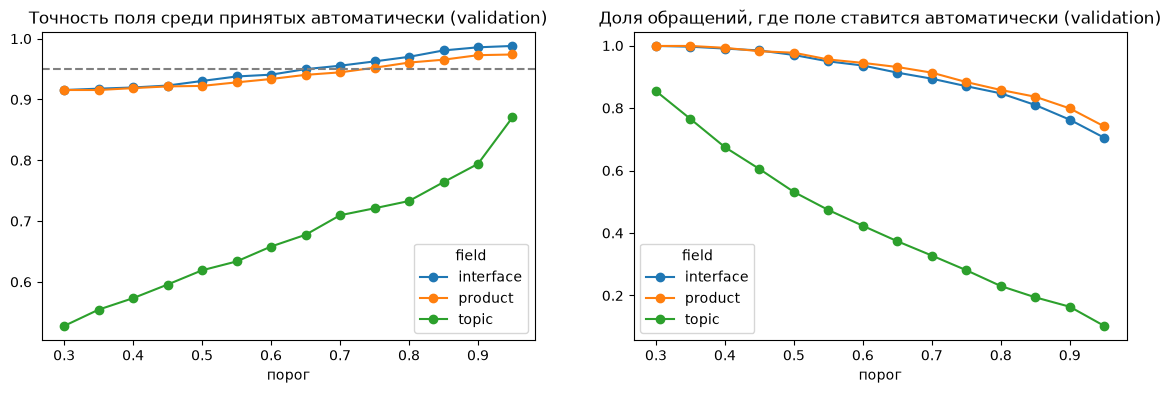

In [39]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))

thresholds_table.pivot(index='threshold', columns='field', values='auto_accuracy').plot(ax=axes[0], marker='o')
axes[0].axhline(TARGET_AUTO_ACCURACY, color='grey', linestyle='--')
axes[0].set_title('Точность поля среди принятых автоматически (validation)')
axes[0].set_xlabel('порог')

thresholds_table.pivot(index='threshold', columns='field', values='auto_share').plot(ax=axes[1], marker='o')
axes[1].set_title('Доля обращений, где поле ставится автоматически (validation)')
axes[1].set_xlabel('порог')

plt.show()

In [40]:
THRESHOLDS = {}
for field in FIELDS:
    table = thresholds_table[thresholds_table['field'] == field]
    good = table[table['auto_accuracy'] >= TARGET_AUTO_ACCURACY]
    # цель недостижима — порог 1.0: уверенность всегда ниже, поле всегда на ручную проверку
    THRESHOLDS[field] = float(good['threshold'].min()) if len(good) > 0 else 1.0

display(f'Пороги уверенности: {THRESHOLDS}')

# что получается для обращения целиком
valid_review = add_review(valid_pred, THRESHOLDS)
auto = ~valid_review['manual_review'].values
all_correct_valid = (valid_review[FIELDS].values == valid[FIELDS].values).all(axis=1)
display(f'validation: на ручную проверку {valid_review["manual_review"].mean():.1%}')
if auto.any():
    display(f'верны все три поля среди принятых автоматически: {all_correct_valid[auto].mean():.1%}')

"Пороги уверенности: {'interface': 0.7, 'product': 0.75, 'topic': 1.0}"

'validation: на ручную проверку 100.0%'

**Вывод:** для интерфейса и продукта цель 95% достигается при порогах 0,70 и 0,75 — автоматически
принимается около 90% обращений по каждому из этих полей. Для тематики цель недостижима ни при каком пороге:
даже при уверенности не ниже 0,95 точность 0,87, и таких обращений лишь 10%. Поэтому порог тематики 1,0 —
она всегда уходит на ручную проверку, а вместе с ней и всё обращение: доля ручной проверки на validation 100%.
Для тематики нужен другой подход — он во втором ноутбуке

## Оценка на тестовой выборке

Модели, порог и правила зафиксированы на train и validation. Теперь один раз проверяем на test (сентябрь)

In [41]:
test_pred = add_review(predict(test, X_test), THRESHOLDS)

res_test = []
for field in FIELDS:
    accuracy, macro_f1 = metrics(test[field], test_pred[field])
    res_test.append({'field': field, 'model': best_by_field[field], 'accuracy': accuracy, 'macro_f1': macro_f1})

res_test = pd.DataFrame(res_test)
res_test.round(3)

,field,model,accuracy,macro_f1
0,interface,xgboost,0.878,0.807
1,product,catboost,0.779,0.682
2,topic,xgboost,0.571,0.390


In [42]:
all_correct = (test_pred[FIELDS].values == test[FIELDS].values).all(axis=1)
auto = ~test_pred['manual_review'].values

display(f'Верны все три поля: {all_correct.mean():.1%}')
display(f'На ручную проверку: {test_pred["manual_review"].mean():.1%}')
if auto.any():
    display(f'Верны все три поля среди принятых автоматически: {all_correct[auto].mean():.1%}')
display(f'Из обращений с ошибкой ушло на ручную проверку: {test_pred["manual_review"].values[~all_correct].mean():.1%}')

'Верны все три поля: 36.9%'

'На ручную проверку: 100.0%'

C:\Users\remote\AppData\Local\Temp\ipykernel_18316\2147891361.py:6: RuntimeWarning: Mean of empty slice
  display(f'Верны все три поля среди принятых автоматически: {all_correct[auto].mean():.1%}')
c:\Users\remote\Desktop\2.3\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


'Верны все три поля среди принятых автоматически: nan%'

'Из обращений с ошибкой ушло на ручную проверку: 100.0%'

По каждому полю отдельно: какая доля ставится автоматически и с какой точностью

In [43]:
rows = []
for field in FIELDS:
    confident = test_pred[f'{field}_confidence'] >= THRESHOLDS[field]
    correct = test_pred[field] == test[field]
    rows.append({'field': field, 'threshold': THRESHOLDS[field],
                 'auto_share': confident.mean(), 'auto_accuracy': correct[confident].mean()})

pd.DataFrame(rows).round(3)

,field,threshold,auto_share,auto_accuracy
0,interface,0.70,0.871,0.933
1,product,0.75,0.820,0.925
2,topic,1.00,0.000,NaN


In [44]:
test_pred['review_reason'].value_counts()

review_reason
низкая уверенность;                                 674
UNKNOWN; низкая уверенность;                        185
низкая уверенность; поля противоречат;               39
UNKNOWN; низкая уверенность; поля противоречат;       7
Name: count, dtype: int64

Насколько помогают доступы и как меняет качество правило заказчика: сравним точность продукта
только по тексту, с учётом доступов и после правила «не уверен → UNKNOWN»

In [45]:
probs_text = best_models[('product', best_by_field['product'])].predict_proba(X_test['product'])
product_text_only = [classes['product'][num] for num in probs_text.argmax(axis=1)]

display(f'Продукт только по тексту: accuracy {accuracy_score(test["product"], product_text_only):.3f}')
display(f'Продукт с учётом доступов: accuracy {accuracy_score(test["product"], test_pred["product_model"]):.3f}')
display(f'Продукт после правила «не уверен → UNKNOWN»: accuracy {accuracy_score(test["product"], test_pred["product"]):.3f}')
display(f'Продукт заменён на UNKNOWN: {(test_pred["product"] != test_pred["product_model"]).sum()} обращений')
display(f'Продукт изменён из-за доступов: {(test_pred["product_source"] == "access").sum()} обращений')

'Продукт только по тексту: accuracy 0.790'

'Продукт с учётом доступов: accuracy 0.852'

'Продукт после правила «не уверен → UNKNOWN»: accuracy 0.779'

'Продукт заменён на UNKNOWN: 156 обращений'

'Продукт изменён из-за доступов: 112 обращений'

### Качество по классам

In [46]:
for field in FIELDS:
    print(f'===== {field} =====')
    print(classification_report(test[field], test_pred[field], zero_division=0))

===== interface =====
                precision    recall  f1-score   support

           API       0.99      0.98      0.98       180
          EFIR       1.00      0.92      0.96        93
   EXCEL_ADDIN       0.98      0.95      0.97        62
EXCEL_TEMPLATE       0.98      0.86      0.92       426
          NONE       0.43      0.85      0.57        67
       UNKNOWN       0.52      0.38      0.44        34
           WEB       0.77      0.86      0.81        43

      accuracy                           0.88       905
     macro avg       0.81      0.83      0.81       905
  weighted avg       0.92      0.88      0.89       905

===== product =====
              precision    recall  f1-score   support

  NO_PRODUCT       0.90      1.00      0.94       445
       RDFOR       1.00      0.56      0.72        59
RD_AFFILIATE       0.95      0.62      0.75        94
     RD_RISK       0.93      0.53      0.68        49
    RD_SCORE       0.97      0.61      0.75        46
 RD_SOLVENCY  

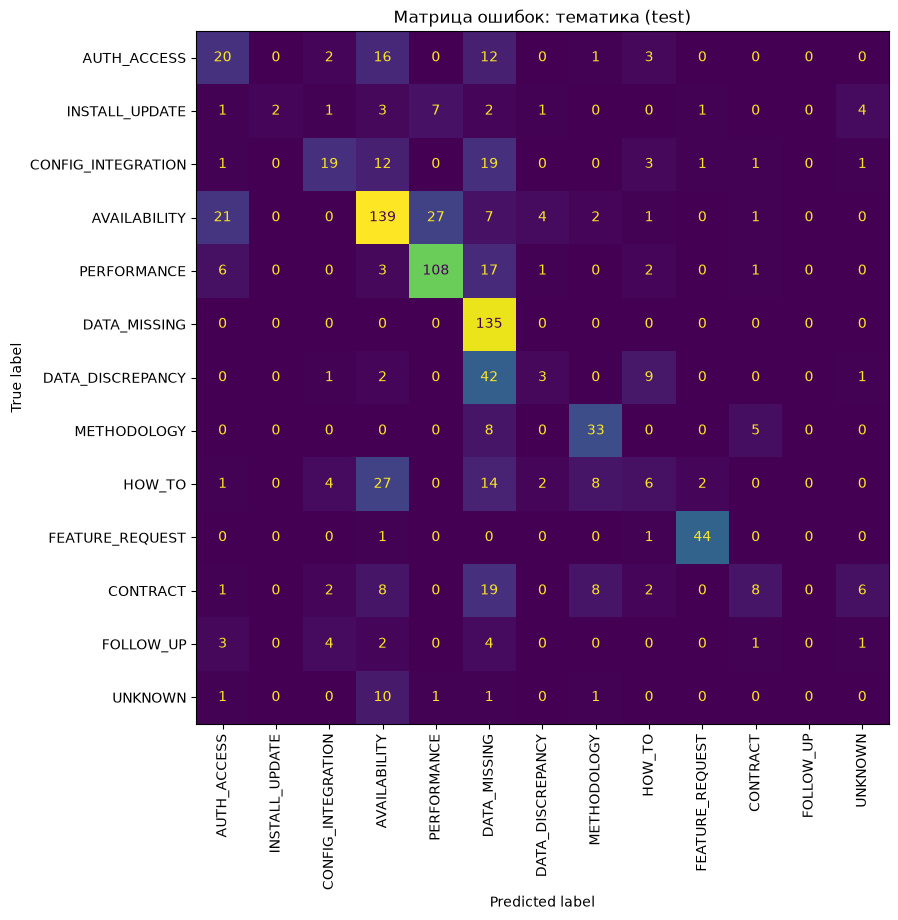

In [47]:
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(test['topic'], test_pred['topic'], labels=classes['topic'],
                                        xticks_rotation=90, colorbar=False, ax=ax)
plt.title('Матрица ошибок: тематика (test)')
plt.show()

**Вывод:**
- Качество на test: интерфейс accuracy 0,878 / macro-F1 0,807, продукт 0,779 / 0,682, тематика 0,571 / 0,390.
  Все три поля верны у 37% обращений.
- По отдельным полям автоматизация работает: интерфейс ставится автоматически у 87% обращений с точностью 93%,
  продукт — у 82% с точностью 93%. Тематика автоматически не принимается, поэтому всё обращение целиком
  уходит на ручную проверку в 100% случаев.
- Точность среди принятых автоматически на test (93%) ниже цели 95%, достигнутой на validation:
  сентябрьский поток отличается от августовского.
- Доступы повышают точность продукта с 0,790 до 0,852. Правило заказчика «нет уверенности → `UNKNOWN`»
  заменило продукт у 156 обращений и снизило точность по разметке до 0,779: среди заменённых были и верные
  продукты, в которых модель была уверена меньше порога. Такие обращения уходят оператору.

## Разбор ошибок

Посмотрим, какие пары «правильно → предсказано» встречаются чаще всего, и на примеры текстов

In [48]:
errors = test.join(test_pred.rename(columns={field: f'{field}_pred' for field in FIELDS}))

for field in FIELDS:
    wrong = errors[errors[field] != errors[f'{field}_pred']]
    display(f'{field}: ошибок {len(wrong)}')
    display(wrong.groupby([field, f'{field}_pred'])['appeal_id'].count()
            .sort_values(ascending=False).head(5).rename('count'))

'interface: ошибок 110'

interface       interface_pred
EXCEL_TEMPLATE  NONE              48
UNKNOWN         NONE              15
EXCEL_TEMPLATE  UNKNOWN           10
NONE            WEB                6
WEB             NONE               6
Name: count, dtype: int64

'product: ошибок 200'

product       product_pred
SPPI_TEST     UNKNOWN         42
RD_AFFILIATE  UNKNOWN         30
RDFOR         UNKNOWN         22
RD_RISK       UNKNOWN         21
RD_SOLVENCY   UNKNOWN         18
Name: count, dtype: int64

'topic: ошибок 388'

topic             topic_pred  
DATA_DISCREPANCY  DATA_MISSING    42
AVAILABILITY      PERFORMANCE     27
HOW_TO            AVAILABILITY    27
AVAILABILITY      AUTH_ACCESS     21
CONTRACT          DATA_MISSING    19
Name: count, dtype: int64

In [49]:
# примеры ошибок по тематике
errors.loc[errors['topic'] != errors['topic_pred'],
           ['text', 'topic', 'topic_pred', 'topic_confidence', 'manual_review']].head(10)

,text,topic,topic_pred,topic_confidence,manual_review
3861,Интеграция с RUDATA идёт через HTTP API. В одном ответе календаря одинаковое событие повторяется дважды с тем же идентификатором. Это увеличивает сумму в нашем расчёте; проверьте дубли.\nГотов уто...,DATA_DISCREPANCY,DATA_MISSING,0.914546,True
3863,Как правильно оформить первое обращение в поддержку RUDATA? Какие диагностические сведения приложить без паролей? Спасибо.,HOW_TO,CONFIG_INTEGRATION,0.433826,True
3864,"Вопрос не о надстройке Excel, а о нашем HTTP-клиенте. API RUDATA, наш программный клиент. Под нашим логином справочник отвечает, а получение истории цен возвращает HTTP 403. Уточните права на этот...",AUTH_ACCESS,DATA_MISSING,0.370133,True
3865,"Добрый день!\nAPI RUDATA, наш программный клиент. В ответе календаря обнаружились повторные события с совпадающими ключами и датами. Нужна проверка целостности данных.\nГотов уточнить детали по за...",DATA_DISCREPANCY,DATA_MISSING,0.928675,True
3869,Прошу помочь с вопросом. Как в Excel-книге набора сведений о контрагентах получить лицензии и статус банкротства для нескольких компаний за один запуск? По возможности ответьте в этой переписке.,HOW_TO,METHODOLOGY,0.271874,True
3877,"Есть несколько вопросов по разным сервисам RUDATA, но описание каждого ещё не подготовлено. Нельзя выделить одну основную тему из этого сообщения. Для нас важно сначала уточнить корректный порядок...",UNKNOWN,AVAILABILITY,0.349332,True
3878,Работаю на сайте RUDATA в браузере. Выгрузка портфеля с сайта не совпала с отображаемым списком инструментов. Фильтры не меняли.,DATA_DISCREPANCY,HOW_TO,0.935344,True
3879,"Речь о компоненте надстройки, а не о конкретном шаблоне. Нужна помощь в интеграции макроса Excel с COM API Add-In: проблема в типах аргументов, а не в токене HTTP. Данные используем для внутренней...",CONFIG_INTEGRATION,DATA_MISSING,0.234351,True
3880,"Добрый день.\nМожно ли согласовать хранение и использование выгрузок во внутренней системе? Нужна консультация по условиям лицензии RUDATA, нужен ответ ответственного за договор специалиста.\nОтве...",CONTRACT,UNKNOWN,0.471371,True
3882,Как в готовой книге сервиса анализа связей компаний выгрузить промежуточные звенья цепочки владения? Для нас важно сначала уточнить корректный порядок действий.,HOW_TO,AVAILABILITY,0.235107,True


In [50]:
# самое опасное — ошибки среди автоматически принятых: их никто не проверит
errors.loc[~all_correct & auto, ['text'] + FIELDS + [f'{field}_pred' for field in FIELDS]].head(10)

,text,interface,product,topic,interface_pred,product_pred,topic_pred


**Вывод:**
- Интерфейс: главная ошибка `EXCEL_TEMPLATE → NONE` (48 случаев) — методологические вопросы к готовому шаблону
  модель относит к «интерфейс не важен». `UNKNOWN` распознаётся плохо (recall 0,38).
- Продукт: больше всего расхождений с разметкой дают замены на `UNKNOWN` по правилу заказчика
  (SPPI-тестирование 42, RD Affiliate 30, RDFOR 22, RD RISK 21, RD Solvency 18).
- Тематика: путаются близкие по смыслу классы — `DATA_DISCREPANCY → DATA_MISSING` (42, расхождение против
  отсутствия данных), `AVAILABILITY → PERFORMANCE` (27, отказ против замедления), `HOW_TO → AVAILABILITY` (27).

Почему тематика слабая: по описанию данных близкие формулировки одного «смыслового семейства» положены в одну
часть выборки. Например, в train `AVAILABILITY` — это в основном «API отвечает timeout» и «сервис не открывается»,
а в test — «в Excel-шаблоне операция обрывается ошибкой, результата нет». Смысл тот же, слова другие.
Модели на словах (TF-IDF) переносят на новые формулировки только то, что видели в train. Удаление слов контекста
частично помогло, но не решило проблему. Интерфейс и продукт определяются хорошо, потому что для них есть
устойчивые слова-маркеры: «API», «шаблон», «RD Score».

## Сохранение модели

Сохраняем всё, что нужно сервису: TF-IDF, SVD, три выбранные модели, порядок классов,
порог и справочник доступов (`models/access.json` сохранён выше)

In [51]:
final_models = {field: best_models[(field, best_by_field[field])] for field in FIELDS}

joblib.dump({'tfidf_word': tfidf_word, 'tfidf_char': tfidf_char, 'svd': svd,
             'tfidf_word_topic': tfidf_word_topic, 'tfidf_char_topic': tfidf_char_topic, 'svd_topic': svd_topic,
             'context_pattern': CONTEXT_PATTERN, 'models': final_models, 'classes': classes},
            'models/classic_model.pkl')

best_params = {row['field']: {'model': row['model'], 'params': row['params']}
               for _, row in res.iterrows() if row['model'] == best_by_field[row['field']]}
model_params = {'thresholds': THRESHOLDS, 'target_auto_accuracy': TARGET_AUTO_ACCURACY,
                'best_models': best_params}

with open('models/classic_params.json', 'w', encoding='utf-8') as f:
    json.dump(model_params, f, ensure_ascii=False, indent=2)

display(f'Размер файла модели: {os.path.getsize("models/classic_model.pkl") / 1024 / 1024:.1f} МБ')

'Размер файла модели: 43.4 МБ'

In [52]:
# результаты для сравнения с подходом на LLM
res.drop(columns='params').to_csv('results/classic_validation.csv', index=False)
res_test.to_csv('results/classic_test.csv', index=False)
test[['appeal_id', 'text'] + FIELDS].join(test_pred.rename(columns={field: f'{field}_pred' for field in FIELDS})).to_csv(
    'results/classic_test_predictions.csv', index=False, encoding='utf-8-sig')

# прогнозы до правил ручной проверки — для гибрида и сравнения в ноутбуке с LLM
for split_name, part, X in [('validation', valid, X_valid), ('test', test, X_test)]:
    part[['appeal_id']].join(predict(part, X)).to_csv(
        f'results/classic_predictions_{split_name}.csv', index=False, encoding='utf-8-sig')

## Выводы

- **Лучшие модели:** XGBoost для интерфейса и тематики, CatBoost для продукта. Качество на test (macro-F1):
  интерфейс 0,81, продукт 0,68 (с правилом заказчика), тематика 0,39.
- **Интерфейс и продукт** классический подход определяет хорошо, быстро и дёшево: интерфейс и продукт
  ставятся автоматически у 82–87% обращений с точностью 93%, прогноз — доли миллисекунды на обращение,
  модель 43 МБ, нужен только процессор.
- **Тематика** этим подходом решается плохо (accuracy 0,57): модели на словах не переносятся на новые формулировки
  того же смысла. Отдельные признаки без слов контекста подняли её с 0,33 до 0,57, но этого недостаточно,
  и из-за тематики всё обращение целиком уходит на ручную проверку.
- **Доступы** повышают точность продукта с 0,79 до 0,85.
- **CatBoost** не даёт выигрыша, оправдывающего время подбора: в 10–40 раз медленнее остальных при сопоставимом качестве.
- Сравнение с языковой моделью и гибридом — во втором ноутбуке (`classify_llm.ipynb`).